# Inter-EOD intervals, 2-fish and 3-fish silent controls

One fish emits every EOD in each recording (2-fish: fish 1; 3-fish: fish 0, the smallest), so the inter-EOD interval
is simply the difference between consecutive EOD times in the recorded table (`Time` column, seconds).
Tables: `*_synch_fix_newest.csv`. All EODs are used, no frame QC.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

REC = {
    '2 fish': 'data/2_fish_silent/Data_2fish_2024-02-13T14_33_21_synch_fix_newest.csv',
    '3 fish': 'data/3_fish_silent/Data_3fish_2024-10-15T14_12_25_synch_fix_newest.csv',
}
COL = {'2 fish': '#2a78d6', '3 fish': '#eb6834'}

iei = {}
for name, path in REC.items():
    t = pd.read_csv(path, usecols=['Time'])['Time'].to_numpy()
    assert np.all(np.diff(t) > 0), name
    iei[name] = np.diff(t) * 1e3          # ms

rows = []
for name, d in iei.items():
    p = np.percentile(d, [1, 5, 25, 50, 75, 95, 99])
    rows.append(dict(recording=name, n_EODs=len(d) + 1, n_intervals=len(d),
                     mean_ms=d.mean(), median_ms=p[3], mode_ms=None,
                     p1=p[0], p5=p[1], p25=p[2], p75=p[4], p95=p[5], p99=p[6],
                     min_ms=d.min(), max_ms=d.max(),
                     n_below_10ms=(d < 10).sum(), n_above_500ms=(d > 500).sum(),
                     rate_Hz_median=1e3 / p[3]))
    h, e = np.histogram(d[d < 500], bins=np.arange(0, 500.5, 1))
    rows[-1]['mode_ms'] = e[h.argmax()] + 0.5
summary = pd.DataFrame(rows).set_index('recording')
summary.round(2).T

recording,2 fish,3 fish
n_EODs,18801.00,19796.00
n_intervals,18800.00,19795.00
mean_ms,54.68,38.99
median_ms,42.20,25.47
mode_ms,38.50,21.50
p1,16.18,16.81
p5,20.14,18.45
p25,33.36,21.77
p75,56.84,31.42
p95,150.76,52.46


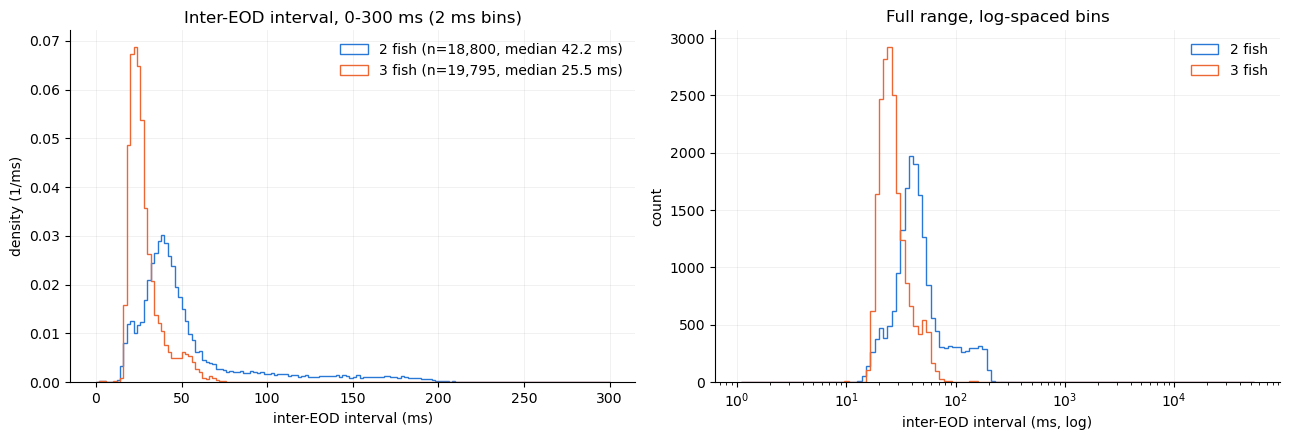

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# linear, 0-300 ms, 2 ms bins, density so the two recordings compare despite different lengths
ax = axes[0]
bins = np.arange(0, 302, 2)
for name, d in iei.items():
    ax.hist(d, bins=bins, density=True, histtype='step', lw=2, color=COL[name],
            label=f"{name} (n={len(d):,}, median {np.median(d):.1f} ms)")
ax.set_xlabel('inter-EOD interval (ms)'); ax.set_ylabel('density (1/ms)')
ax.set_title('Inter-EOD interval, 0-300 ms (2 ms bins)')
ax.legend(frameon=False)

# log x, full range
ax = axes[1]
lbins = np.logspace(np.log10(min(d.min() for d in iei.values())),
                    np.log10(max(d.max() for d in iei.values())), 120)
for name, d in iei.items():
    ax.hist(d, bins=lbins, histtype='step', lw=2, color=COL[name], label=name)
ax.set_xscale('log'); ax.set_xlabel('inter-EOD interval (ms, log)'); ax.set_ylabel('count')
ax.set_title('Full range, log-spaced bins')
ax.legend(frameon=False)
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(alpha=0.25, lw=0.5)
plt.tight_layout(); plt.show()

Cumulative distribution and interval over time (to see whether the rhythm drifts or has gaps).

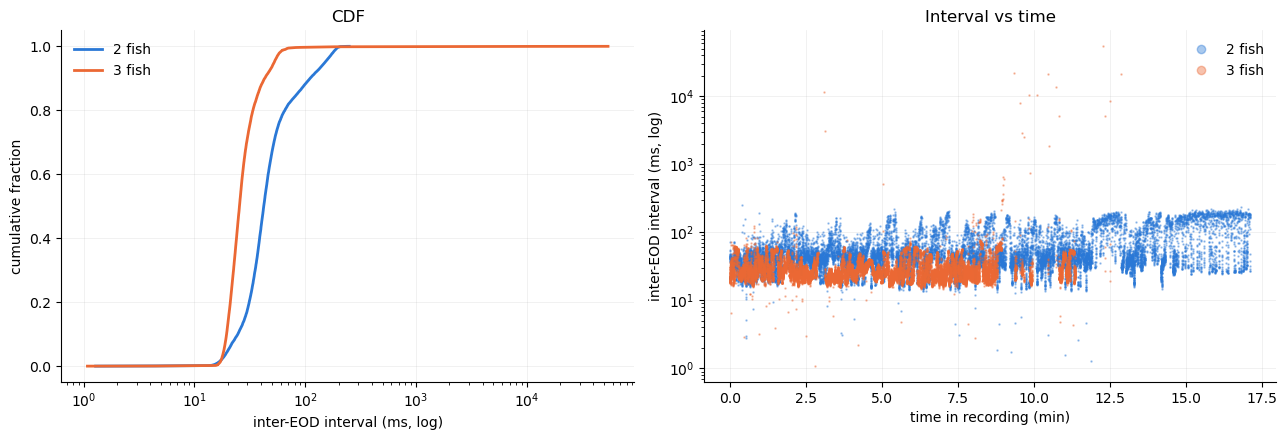

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
for name, d in iei.items():
    s = np.sort(d)
    ax.plot(s, np.arange(1, len(s) + 1) / len(s), lw=2, color=COL[name], label=name)
ax.set_xscale('log'); ax.set_xlabel('inter-EOD interval (ms, log)'); ax.set_ylabel('cumulative fraction')
ax.set_title('CDF'); ax.legend(frameon=False)

ax = axes[1]
for name, path in REC.items():
    t = pd.read_csv(path, usecols=['Time'])['Time'].to_numpy()
    ax.plot(t[1:] / 60, iei[name], '.', ms=1.5, alpha=0.4, color=COL[name], label=name)
ax.set_yscale('log'); ax.set_xlabel('time in recording (min)'); ax.set_ylabel('inter-EOD interval (ms, log)')
ax.set_title('Interval vs time'); ax.legend(frameon=False, markerscale=8)
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(alpha=0.25, lw=0.5)
plt.tight_layout(); plt.show()

In [4]:
# the longest gaps (possible recording breaks) and the shortest intervals (possible double detections)
for name, path in REC.items():
    t = pd.read_csv(path, usecols=['Frame', 'Time'])
    d = np.diff(t['Time'].to_numpy()) * 1e3
    o = np.argsort(d)
    print(name)
    print('  5 shortest (ms):', np.round(d[o[:5]], 2), 'at frames', t['Frame'].to_numpy()[o[:5] + 1])
    print('  5 longest  (ms):', np.round(d[o[-5:]], 1), 'at frames', t['Frame'].to_numpy()[o[-5:] + 1])

2 fish
  5 shortest (ms): [1.28 1.58 1.76 1.86 2.6 ] at frames [35691 33111 27809 26333 34342]
  5 longest  (ms): [217.2 220.4 223.  237.6 249.5] at frames [47507 16170 51202 50456  1160]


3 fish
  5 shortest (ms): [1.08 2.2  2.8  2.94 3.04] at frames [ 8438 12653 24178  1375  7518]
  5 longest  (ms): [13444.5 21393.8 21542.1 21633.6 54115. ] at frames [32211 38575 31426 28102 36808]
